## Project: Gyroid structure vs mechanical strength

This project investigates whether gyroid infill exhibits different tensile strength from selected alternative infill patterns in PLA+ specimens at comparable infill densities and recorded printing conditions.A secondary exploratory analysis will examine whether their magnitude varies with infill density, layer thickness, or printing speed. Material-dependent and printer-type-dependent gyroid effects will not be investigated because the dataset contains gyroid observations only for PLA+ printed in a closed chamber.
The repository describes 500 experimental samples, ten filament materials, and multiple infill patterns, including gyroid

## DATASET 
-Input / Process Parameters: 
* Printer Type: Open vs. Closed chamber printers
* Material Types (10 different filaments): PLA+, PLA, PLA phosphor (fosfor), PLACF (carbon fiber), PLA-transparent (şeffaf), PETG, rPET (recycled PET), PP, TPU, and
ABS.
* Layer Thickness (mm): Variable layer resolutions.
* Infill Density (%): Variable infill percentages.
* Infill Pattern (15 different patterns): Grid, Triangles, Zigzag, Lines, Cubic, Quarter
Cubic, Cross, Gyroid, Cubic Subdivision, Tri-hexagon, Lightning, Cross3D,
Concentric, and Octet.
* Printing Speed (mm/s): Controlled extrusion speeds.
* Specimen Dimensions: Width (mm) and Thickness (mm) of each printed sample.

-Output / Characterization Results:
* Surface Roughness (Roughness AVG - µm): Average surface roughness
measurements.
* Hardness (Hardness AVG): Shore hardness characterization.
* Tensile Properties: Peak Load (N), Peak Stress (kPa), Strain at Break (mm/mm), and
Elastic Modulus (MPa)


In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt

## Data Preparation

* Variables that will be conisdered in the dataframe: 
- Sample No
- Material 
- Printer Type 
- Infill Pattern	
- Infill Density (%) 
- Layer Thickness (mm)	
- Speed (mm/s)	
- Peak Stress (kPa)	
- Width (mm), Thickness (mm)	
- Peak Load (N) (Useful for checking Peak Stress; but not used as a strength predictor)

In [2]:
df = pd.read_csv("3d-printing-dataset.csv")
df.head()

,Sample No,Printer Type,Material,Layer Thickness (mm),Infill Density (%),Infill Pattern,Speed ​​(mm/s),Roughness AVG,Hardness AVG,Peak Load (N),Peak Stress (kPa),Strain at Break (mm/mm),Modulus (MPa),Width (mm),Thickness (mm)
0,1,closed,PLA+,0.1,20,Grid,30,2.579000,54.3,518.848000,24755.066667,0.013667,2128.810667,6.116667,3.426667
1,2,closed,PLA+,0.1,20,Grid,50,2.836333,60.9,477.144333,22743.133333,0.013000,2068.996000,6.063333,3.460000
2,3,closed,PLA+,0.1,20,Grid,70,3.271667,62.4,481.243000,21676.166667,0.012333,2009.842333,6.383333,3.480000
3,4,closed,PLA+,0.1,20,Triangles,30,2.570333,61.5,465.988667,21275.933333,0.012000,2065.603000,6.246667,3.506667
4,5,closed,PLA+,0.1,20,Triangles,50,2.717667,63.8,475.511000,22436.366667,0.012333,2050.737667,6.173333,3.433333


Lets us check if the dataset has missing values, and calculate the total number of missing values. 

In [3]:
# Count missing values in each column
print("Missing values per column:")
print(df.isna().sum())

# Count missing values across the entire dataset
print("\nTotal missing values:", df.isna().sum().sum())

# Display rows containing at least one missing value
display(df[df.isna().any(axis=1)])

Missing values per column:
Sample No                   0
Printer Type                0
Material                    0
Layer Thickness (mm)        0
Infill Density (%)          0
Infill Pattern              0
Speed ​​(mm/s)              0
Roughness AVG               0
Hardness AVG                0
Peak Load (N)               0
Peak Stress (kPa)           0
Strain at Break (mm/mm)    47
Modulus (MPa)               0
Width (mm)                  0
Thickness (mm)              0
dtype: int64

Total missing values: 47


,Sample No,Printer Type,Material,Layer Thickness (mm),Infill Density (%),Infill Pattern,Speed ​​(mm/s),Roughness AVG,Hardness AVG,Peak Load (N),Peak Stress (kPa),Strain at Break (mm/mm),Modulus (MPa),Width (mm),Thickness (mm)
153,154,closed,PETG,0.1,20,Grid,30,3.011000,42.0,661.039667,31047.433333,NaN,1761.503667,6.233333,3.416667
154,155,closed,PETG,0.1,20,Grid,50,4.578333,40.1,649.442333,30197.066667,NaN,1657.813333,6.240000,3.446667
155,156,closed,PETG,0.1,20,Grid,70,5.503000,34.6,663.123333,31968.433333,NaN,1832.154333,6.083333,3.410000
158,159,closed,PETG,0.1,20,Triangles,70,1.452333,53.7,738.977000,34102.666667,NaN,1895.323000,6.293333,3.443333
161,162,closed,PETG,0.1,20,Zigzag,70,1.972000,50.5,670.551333,32282.600000,NaN,1842.565333,6.156667,3.373333
167,168,closed,PETG,0.1,50,Triangles,70,1.697333,72.0,737.662667,34169.766667,NaN,2092.189000,6.270000,3.443333
170,171,closed,PETG,0.1,50,Zigzag,70,1.607000,69.5,768.832000,33917.400000,NaN,1979.228333,6.680000,3.393333
175,176,closed,PETG,0.1,80,Triangles,50,1.595667,74.4,785.588667,34990.566667,NaN,2294.103000,6.630000,3.386667
176,177,closed,PETG,0.1,80,Triangles,70,2.069000,73.6,783.318000,36488.133333,NaN,2384.259000,6.216667,3.453333
180,181,closed,PETG,0.2,20,Grid,30,2.904667,67.7,693.017667,31190.633333,NaN,1943.916333,6.473333,3.433333


We can observe that the column in Strain at break (mm/mm) are missing but our response variable is Peak Stress; strain at break is not in our objective because it's a mechanical response that is not in our interest. 

 Cleaning column names and category lables, which fixes inconsistencies in the data, e.g closed vs closed or grid vs grid

In [4]:
# Preserve the imported data
data = df.copy()

# Remove invisible characters and extra spaces from column names
data.columns = (
    data.columns
    .str.replace("\u200b", "", regex=False)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Clean category labels
data["Material"] = data["Material"].str.strip()
data["Printer Type"] = data["Printer Type"].str.strip().str.lower()

data["Infill Pattern"] = (
    data["Infill Pattern"]
    .str.strip()
    .str.lower()
    .replace({"zig zag": "zigzag"})
)

Now we select our material (PLA+), printer (closed) and comparison patterns, which defines the project scope. We will keep material and printer constant, and only for documentation purposes. For this first analysis let us keep gyroid,  triangles, zigzag and grid. 

In [5]:
patterns = ["gyroid", "triangles", "zigzag", "grid"]

analysis_df = data.loc[
    (data["Material"] == "PLA+")
    & (data["Printer Type"] == "closed")
    & (data["Infill Pattern"].isin(patterns))
].copy()

Keep the relavant columns. 

In [6]:
columns_to_keep = [
    "Sample No",
    "Material",
    "Printer Type",
    "Infill Pattern",
    "Infill Density (%)",
    "Layer Thickness (mm)",
    "Speed (mm/s)",
    "Peak Stress (kPa)",
    "Peak Load (N)",
    "Width (mm)",
    "Thickness (mm)"
]

analysis_df = analysis_df[columns_to_keep]

Let us observe the number of samples per pattern at each density infill while also displaying the cleaned data that we want. 

In [7]:
# Number of rows and columns
print("Working table shape:", analysis_df.shape)

# Missing values
print("\nMissing values:")
print(analysis_df.isna().sum())

# Samples per pattern at each density
display(
    pd.crosstab(
        analysis_df["Infill Pattern"],
        analysis_df["Infill Density (%)"]
    )
)

# Preview the cleaned table
display(analysis_df.head())

Working table shape: (94, 11)

Missing values:
Sample No               0
Material                0
Printer Type            0
Infill Pattern          0
Infill Density (%)      0
Layer Thickness (mm)    0
Speed (mm/s)            0
Peak Stress (kPa)       0
Peak Load (N)           0
Width (mm)              0
Thickness (mm)          0
dtype: int64


Infill Density (%),20,50,80
Infill Pattern,,,
grid,9,9,9
gyroid,3,4,6
triangles,9,9,9
zigzag,9,9,9


,Sample No,Material,Printer Type,Infill Pattern,Infill Density (%),Layer Thickness (mm),Speed (mm/s),Peak Stress (kPa),Peak Load (N),Width (mm),Thickness (mm)
0,1,PLA+,closed,grid,20,0.1,30,24755.066667,518.848000,6.116667,3.426667
1,2,PLA+,closed,grid,20,0.1,50,22743.133333,477.144333,6.063333,3.460000
2,3,PLA+,closed,grid,20,0.1,70,21676.166667,481.243000,6.383333,3.480000
3,4,PLA+,closed,triangles,20,0.1,30,21275.933333,465.988667,6.246667,3.506667
4,5,PLA+,closed,triangles,20,0.1,50,22436.366667,475.511000,6.173333,3.433333


We can see that we have in total 13 gyroid samples that can be extracted and compared with in this data. We will keep the specimen dimensions (Width and Thickness) for checking our stress calculations. Peak load will be considered as strength predicitor. 

We can think about a model sequence on how to progress in this project: 
1) Model 0: Mean baseline -> predict the training-set average strength
2) Model 1: Density only -> Infill density
3) Model 2: Density + pattern -> Density and dummy-coded infill pattern: Do patterns differ, assuming the same density–strength slope?
4) Model 3: Adjusted model	-> Model 2 + layer thickness + printing speed: Do the pattern differences remain after accounting for these printing conditions?
5) Model 4: Interaction model	-> Model 3 + density × pattern: Does the gyroid–reference difference change with density?
6) Model 5: Polynomial extension	-> Model 4 + selected quadratic terms: Does allowing curvature improve the model?

Let us create a table showing the sample count, mean strength and spread. This is only discriptive, as density is not the only setting that differs between the specimens being averaged. So, if two patterns have different average strengths, we cannot immediately attribute the whole difference to the pattern.

In [8]:
strength_summary = (
    analysis_df
    .groupby(["Infill Pattern", "Infill Density (%)"])
    ["Peak Stress (kPa)"]
    .agg(
        n="count",
        mean_strength="mean",
        std_strength="std"
    )
    .round(2)
)

display(strength_summary)

n  mean_strength  std_strength
Infill Pattern Infill Density (%)                                
grid           20                  9       28469.54       4832.01
               50                  9       30263.39       4927.27
               80                  9       34997.80       3603.35
gyroid         20                  3       30627.20       3111.68
               50                  4       42132.28       2805.11
               80                  6       40619.98       4341.85
triangles      20                  9       28086.94       5207.79
               50                  9       30935.42       4904.62
               80                  9       35156.08       2727.52
zigzag         20                  9       27998.20       4488.20
               50                  9       31613.94       4066.54
               80                  9       37834.76       1939.72

The next plot helps us inspect:

* Whether strength tends to increase with density.

* How much observations vary within each density.

* Whether gyroid appears different from the reference patterns.

* Whether any values need investigation.

In [ ]:
%pip install seaborn

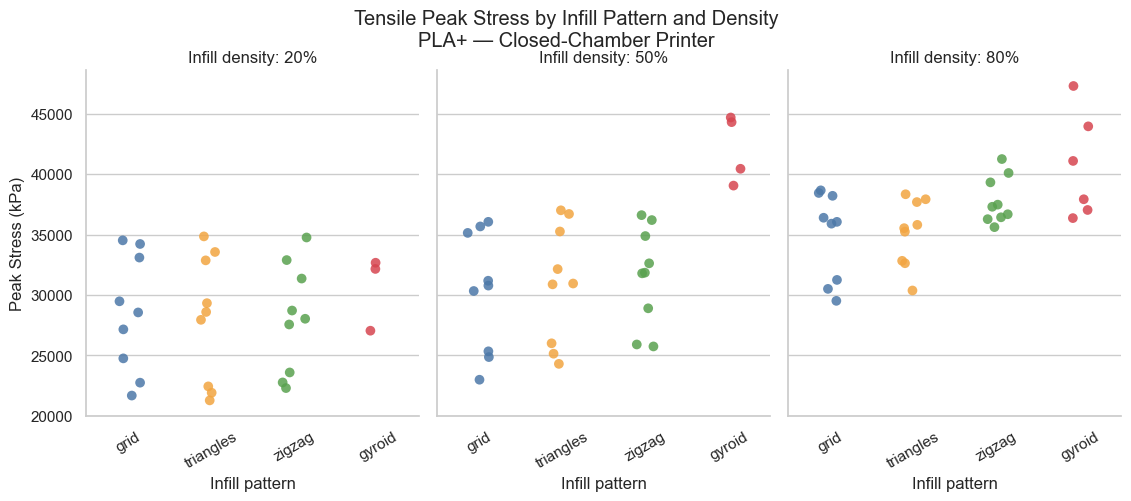

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

pattern_order = ["grid", "triangles", "zigzag", "gyroid"]

palette = {
    "grid": "#4C78A8",
    "triangles": "#F2A541",
    "zigzag": "#59A14F",
    "gyroid": "#D64550"
}

g = sns.catplot(
    data=analysis_df,
    x="Infill Pattern",
    y="Peak Stress (kPa)",
    hue="Infill Pattern",
    col="Infill Density (%)",
    order=pattern_order,
    hue_order=pattern_order,
    col_order=[20, 50, 80],
    kind="strip",
    jitter=0.15,
    palette=palette,
    size=7,
    alpha=0.85,
    height=4.5,
    aspect=0.85,
    sharey=True,
    legend=False
)

g.set_titles("Infill density: {col_name}%")
g.set_axis_labels("Infill pattern", "Peak Stress (kPa)")

for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="x", visible=False)

g.figure.suptitle(
    "Tensile Peak Stress by Infill Pattern and Density\n"
    "PLA+ — Closed-Chamber Printer",
    y=1.05
)

plt.show()


# Model 0: Mean-strength baseline

Let us try to predict the same average Peak Stress for every specimen, which ignores infill pattern, density, speed, and layer thickness. Its purpose is to provide a simple benchmark that our later regression models should improve upon. 

For now we only calculate the average using only training data but not the complete dataset. We compare models using cross-validation within the training set. This follows the training-based baseline approach illustrated in scikit-learn’s learning materials. 

In [10]:
import pandas as pd

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.dummy import DummyRegressor

# Predictor columns for later models
features = [
    "Infill Density (%)",
    "Infill Pattern",
    "Layer Thickness (mm)",
    "Speed (mm/s)"
]

X = analysis_df[features].copy()
y = analysis_df["Peak Stress (kPa)"].copy()

# Keep the same split for all subsequent models
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=X["Infill Pattern"]
)

print("Training specimens:", len(y_train))
print("Reserved test specimens:", len(y_test))

Training specimens: 75
Reserved test specimens: 19


Model 0 ignores the predictor column values. Stratification here keeps the pattern proportions approximately similar in training and test data.

Model 0 : Fit


In [11]:
model_0 = DummyRegressor(strategy="mean")

model_0.fit(X_train, y_train)

# Every training specimen receives the same prediction
predictions_0 = model_0.predict(X_train)

print(f"Model 0 prediction: {y_train.mean():,.2f} kPa")

display(
    pd.DataFrame({
        "Actual Peak Stress (kPa)": y_train,
        "Predicted Peak Stress (kPa)": predictions_0
    }).head(10)
)

Model 0 prediction: 32,710.95 kPa


,Actual Peak Stress (kPa),Predicted Peak Stress (kPa)
77,38344.133333,32710.949778
22,32632.466667,32710.949778
41,32147.033333,32710.949778
8,22296.366667,32710.949778
72,38667.833333,32710.949778
373,37929.933333,32710.949778
46,36059.133333,32710.949778
4,22436.366667,32710.949778
27,27156.900000,32710.949778
66,35261.166667,32710.949778


The predicted column should contain the same number in every row. That is intentional: Model 0 makes no distinction between specimens.The actual Peak Stress varies between specimens—for example, 38,344.13 kPa and 22,296.37 kPa.

Evaluating the baseline using cross-validation. During cross-validation, the baseline average is recalculated using only the training portion of each fold.

In [12]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores_0 = cross_validate(
    model_0,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "MSE": "neg_mean_squared_error"
    }
)

model_0_results = pd.DataFrame({
    "Model": ["Model 0: Mean baseline"],
    "CV MAE (kPa)": [-scores_0["test_MAE"].mean()],
    "CV RMSE (kPa)": [
        ((-scores_0["test_MSE"]) ** 0.5).mean()
    ]
})

display(model_0_results.round(2))

,Model,CV MAE (kPa),CV RMSE (kPa)
0,Model 0: Mean baseline,4755.9,5754.64


Lower values indicate better prediction. These are benchmark errors—not estimates of a gyroid effect.

* MAE: Average absolute prediction error, in kPa
* RMSE: Prediction error in kPa that gives greater weight to large errors